# Notebook 0: Introduction & Core Concepts

## Learning Objectives

By the end of this notebook you will understand:
1. **Why** traditional ADSR envelopes are limited for expressive music
2. **What** the HH-Inspired Envelope Unit (HEU) is and how it works
3. **How** the internal gates (attack, recovery) create musical dynamics
4. **The role of tonic drive** in sustaining envelopes
5. **The refractory period** and why it matters for rhythmic spacing

---

In [1]:
import sys

sys.path.insert(0, "..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np

from hh_envelope.core import HEUConfig, HHEnvelopeUnit
from notebooks.utils.audio import display_audio, envelope_to_audio
from notebooks.utils.plotting import (
    plot_gate_dynamics,
    setup_notebook_style,
)
from notebooks.utils.signals import run_heu_simulation, run_heu_with_gates

setup_notebook_style()
print("Setup complete.")

Setup complete.


## 1. The Problem: Traditional ADSR Envelopes

Traditional synthesizer envelopes use an **ADSR** (Attack-Decay-Sustain-Release) model:

- **Externally triggered**: "Play this shape now"
- **Open-loop**: No feedback, no memory of what just happened
- **Non-adaptive**: Same shape regardless of context (dynamics, tempo, preceding notes)

This works for simple synthesis but fails to capture the **reactive, context-sensitive** nature of real musical articulation.

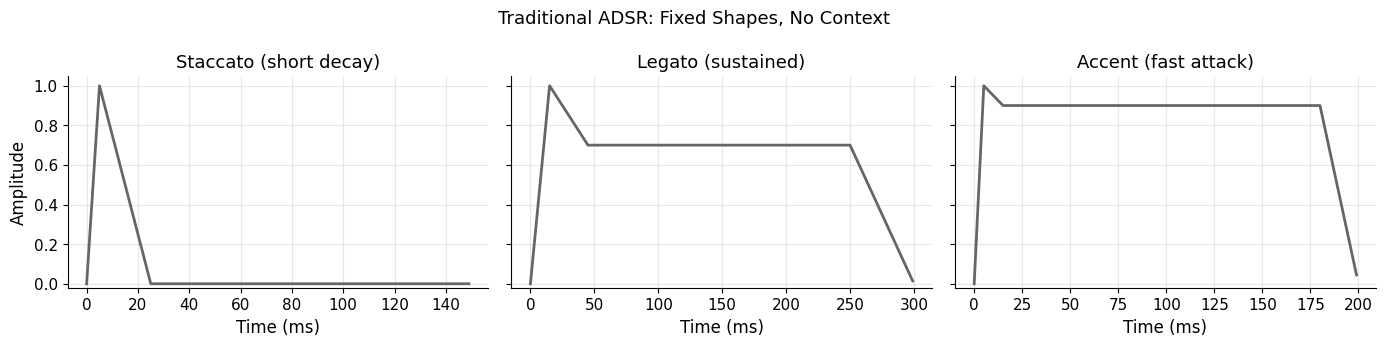

Notice: Each shape is pre-programmed. The envelope has no 'opinion' about what it should do.


In [2]:
def traditional_adsr(attack_ms=10, decay_ms=30, sustain_level=0.7, release_ms=50, duration_ms=200):
    """Generate a traditional ADSR envelope."""
    envelope = np.zeros(duration_ms)
    t = 0

    # Attack: linear ramp to 1.0
    for i in range(min(attack_ms, duration_ms)):
        envelope[t] = i / attack_ms
        t += 1

    # Decay: linear ramp to sustain_level
    for i in range(min(decay_ms, duration_ms - t)):
        envelope[t] = 1.0 - (1.0 - sustain_level) * (i / decay_ms)
        t += 1

    # Sustain: flat
    sustain_end = duration_ms - release_ms
    while t < sustain_end:
        envelope[t] = sustain_level
        t += 1

    # Release: linear ramp to 0
    release_start = t
    while t < duration_ms:
        progress = (t - release_start) / max(1, release_ms)
        envelope[t] = sustain_level * (1 - progress)
        t += 1

    return np.clip(envelope, 0, 1)


# Show three ADSR variants
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)

configs = [
    {"attack_ms": 5, "decay_ms": 20, "sustain_level": 0.0, "release_ms": 30, "duration_ms": 150},
    {"attack_ms": 15, "decay_ms": 30, "sustain_level": 0.7, "release_ms": 50, "duration_ms": 300},
    {"attack_ms": 5, "decay_ms": 10, "sustain_level": 0.9, "release_ms": 20, "duration_ms": 200},
]
titles = ["Staccato (short decay)", "Legato (sustained)", "Accent (fast attack)"]

for ax, cfg, title in zip(axes, configs, titles):
    env = traditional_adsr(**cfg)
    ax.plot(env, linewidth=2, color="#666")
    ax.set_title(title)
    ax.set_xlabel("Time (ms)")
    ax.set_ylim([-0.02, 1.05])

axes[0].set_ylabel("Amplitude")
fig.suptitle("Traditional ADSR: Fixed Shapes, No Context", fontsize=13)
plt.tight_layout()
plt.show()

print(
    "Notice: Each shape is pre-programmed. The envelope has no 'opinion' about what it should do."
)

## 2. The HH-Inspired Solution: Excitable Dynamics

The **HH-Inspired Envelope Unit (HEU)** borrows from Hodgkin-Huxley neuron dynamics:

| Neuroscience | Musical Envelope |
|---|---|
| Membrane voltage | Envelope amplitude |
| Na+ activation (fast) | Attack gate |
| K+ activation (slow) | Recovery gate |
| Injected current | Excitation (onset energy) |
| Refractory period | Minimum inter-note spacing |
| Tonic firing | Sustained envelope via tonic drive |

### Key Property: **Self-Amplifying Transients**

When excitation pushes the envelope above a threshold:
1. Attack gate opens rapidly (positive feedback)
2. Envelope amplifies its own rise
3. Recovery gate follows slowly (negative feedback)
4. Envelope returns to baseline
5. Refractory period prevents immediate re-triggering

This creates **organic, context-sensitive** envelopes that *react* to input rather than replaying shapes.

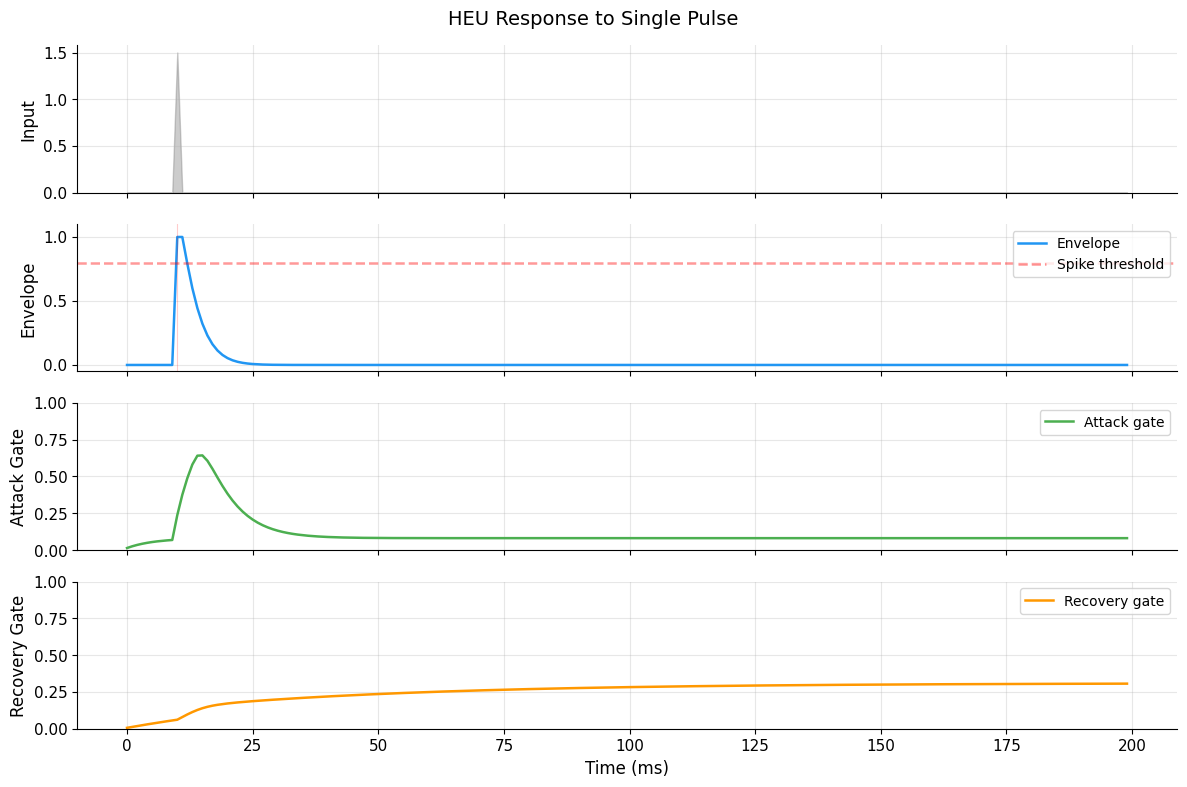

Peak envelope: 1.000
Time to peak: 10 ms
Spike events: 1

Notice how:
  - Attack gate rises FAST (positive feedback)
  - Recovery gate follows SLOWLY (delayed negative feedback)
  - Envelope decays as recovery overwhelms attack


In [3]:
# Create an HEU with default parameters
unit = HHEnvelopeUnit()

# Single pulse input
duration_ms = 200
input_signal = np.zeros(duration_ms)
input_signal[10] = 1.5  # Single pulse at t=10ms

# Run simulation capturing gate dynamics
result = run_heu_with_gates(unit, input_signal, dt_ms=1.0)

# Plot the full gate dynamics
fig = plot_gate_dynamics(
    voltage=result.envelope,
    attack_gate=result.attack_gate,
    recovery_gate=result.recovery_gate,
    time_ms=result.time_ms,
    input_signal=result.input_signal,
    spike_times=result.spike_times,
    title="HEU Response to Single Pulse",
)
plt.show()

print(f"Peak envelope: {result.envelope.max():.3f}")
print(f"Time to peak: {np.argmax(result.envelope)} ms")
print(f"Spike events: {len(result.spike_times)}")
print("\nNotice how:")
print("  - Attack gate rises FAST (positive feedback)")
print("  - Recovery gate follows SLOWLY (delayed negative feedback)")
print("  - Envelope decays as recovery overwhelms attack")

## 3. Comparing ADSR vs HEU

Let's directly compare the two approaches to the same musical idea: a single note attack.

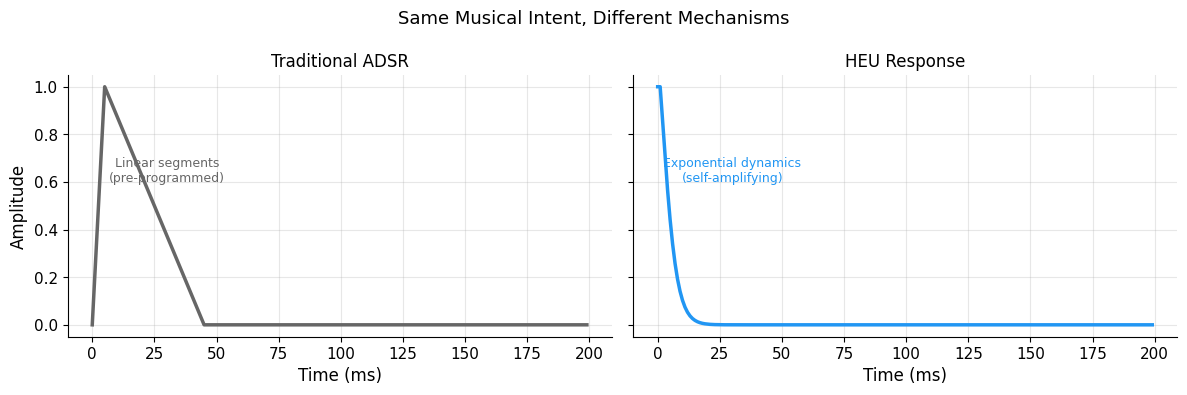

The HEU produces naturally curved transients through feedback dynamics,
not by connecting linear segments.


In [4]:
# Generate both envelopes for comparison
adsr_env = traditional_adsr(
    attack_ms=5, decay_ms=40, sustain_level=0.0, release_ms=50, duration_ms=200
)

unit = HHEnvelopeUnit()
input_signal = np.zeros(200)
input_signal[0] = 1.5
heu_env, _ = run_heu_simulation(unit, input_signal)

# Side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax1.plot(adsr_env, linewidth=2.5, color="#666")
ax1.set_title("Traditional ADSR", fontsize=12)
ax1.set_xlabel("Time (ms)")
ax1.set_ylabel("Amplitude")
ax1.annotate(
    "Linear segments\n(pre-programmed)", xy=(30, 0.6), fontsize=9, ha="center", color="#666"
)

ax2.plot(heu_env, linewidth=2.5, color="#2196F3")
ax2.set_title("HEU Response", fontsize=12)
ax2.set_xlabel("Time (ms)")
ax2.annotate(
    "Exponential dynamics\n(self-amplifying)",
    xy=(30, 0.6),
    fontsize=9,
    ha="center",
    color="#2196F3",
)

fig.suptitle("Same Musical Intent, Different Mechanisms", fontsize=13)
plt.tight_layout()
plt.show()

print("The HEU produces naturally curved transients through feedback dynamics,")
print("not by connecting linear segments.")

## 4. The Role of Tonic Drive

A key feature of the HEU is **tonic drive**: a continuous low-level excitation that sustains the envelope.

This is the analog of a musician's sustained breath, bow pressure, or key hold.

- **Without tonic**: Envelope decays after transient (staccato)
- **With tonic**: Envelope sustains at a high level (legato)

The HEU amplifies the tonic through positive feedback, so a small input (~0.15-0.35) produces a large sustained output (~0.7-0.9).

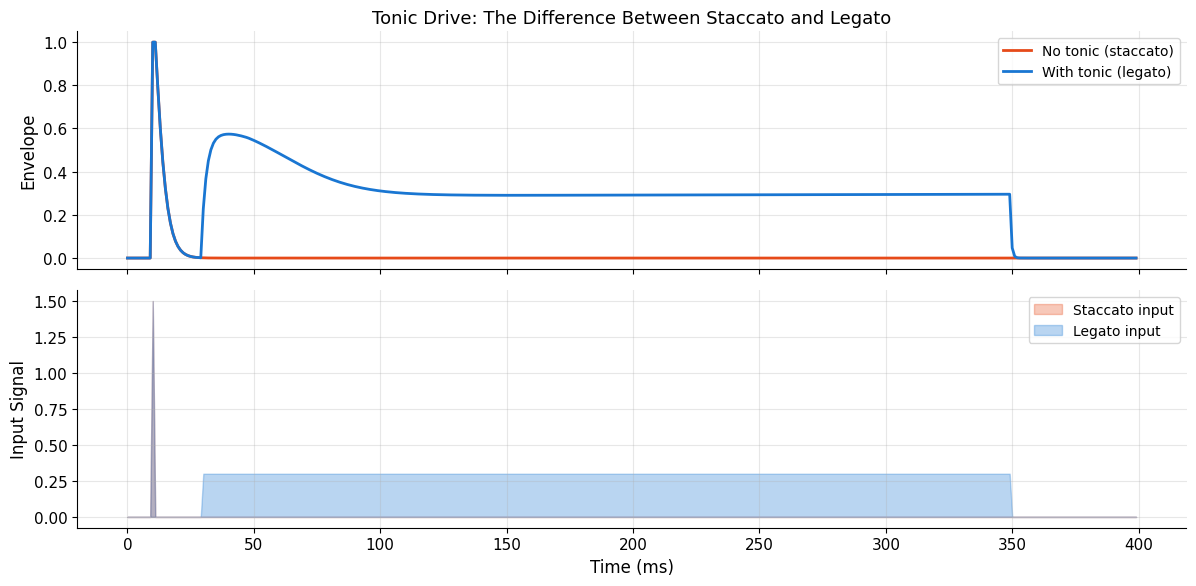

Staccato peak: 1.000, decays to ~0 by 100ms
Legato sustain: 0.292 (input = 0.3, output > 0.7)

The HEU AMPLIFIES small tonic input through positive feedback.


In [5]:
# Compare: no tonic vs tonic drive
duration_ms = 400

# Staccato: pulse only, no tonic
unit_staccato = HHEnvelopeUnit()
sig_staccato = np.zeros(duration_ms)
sig_staccato[10] = 1.5
result_staccato = run_heu_with_gates(unit_staccato, sig_staccato)

# Legato: pulse + tonic from t=30 onward
unit_legato = HHEnvelopeUnit()
sig_legato = np.zeros(duration_ms)
sig_legato[10] = 1.5
# Use tonic as part of the excitation signal (simulating sustained input)
sig_legato[30:350] = 0.3  # Tonic drive
result_legato = run_heu_with_gates(unit_legato, sig_legato)

# Plot comparison
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(
    result_staccato.time_ms,
    result_staccato.envelope,
    color="#E64A19",
    linewidth=2,
    label="No tonic (staccato)",
)
axes[0].plot(
    result_legato.time_ms,
    result_legato.envelope,
    color="#1976D2",
    linewidth=2,
    label="With tonic (legato)",
)
axes[0].set_ylabel("Envelope")
axes[0].legend()
axes[0].set_title("Tonic Drive: The Difference Between Staccato and Legato")

axes[1].fill_between(
    result_staccato.time_ms, 0, sig_staccato, alpha=0.3, color="#E64A19", label="Staccato input"
)
axes[1].fill_between(
    result_legato.time_ms, 0, sig_legato, alpha=0.3, color="#1976D2", label="Legato input"
)
axes[1].set_ylabel("Input Signal")
axes[1].set_xlabel("Time (ms)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Staccato peak: {result_staccato.envelope.max():.3f}, decays to ~0 by 100ms")
print(f"Legato sustain: {result_legato.envelope[200]:.3f} (input = 0.3, output > 0.7)")
print("\nThe HEU AMPLIFIES small tonic input through positive feedback.")

## 5. Refractory Period: Rhythmic Spacing

After a spike event (envelope exceeds threshold), the HEU enters a **refractory period** during which it cannot spike again.

Default: 20ms refractory period.

This prevents double-triggering on closely-spaced pulses and creates natural rhythmic spacing.

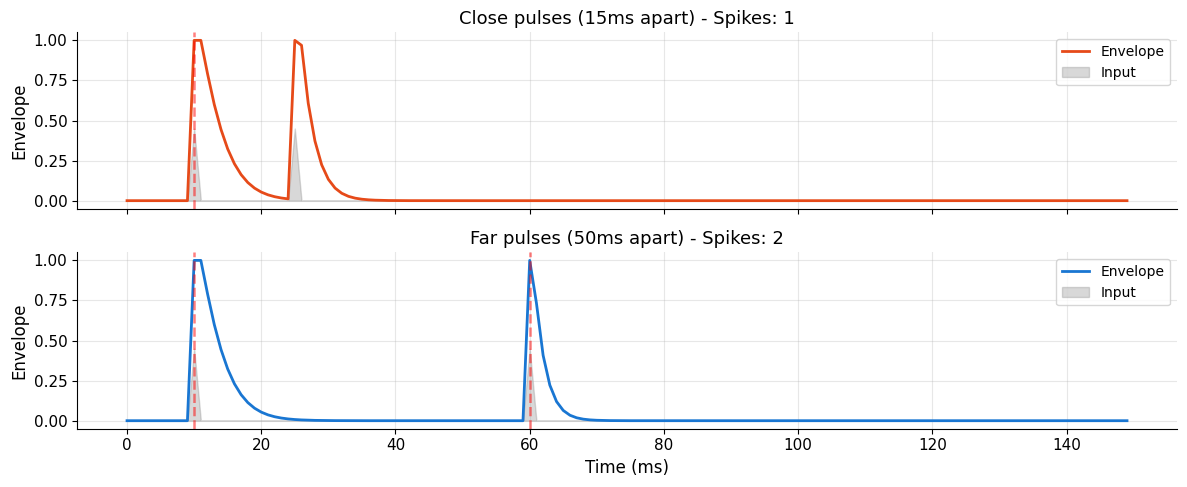

Close pulses (15ms): 1 spike(s) - second pulse suppressed
Far pulses (50ms): 2 spike(s) - both pulses trigger

Refractory period prevents double-triggering on grace notes, flams, etc.


In [6]:
# Demonstrate refractory period
unit = HHEnvelopeUnit()
duration_ms = 150

# Two pulses: one at t=10, one at t=25 (only 15ms apart - within refractory)
input_close = np.zeros(duration_ms)
input_close[10] = 1.5
input_close[25] = 1.5  # Within 20ms refractory
result_close = run_heu_with_gates(unit, input_close)

# Two pulses: one at t=10, one at t=60 (50ms apart - outside refractory)
unit2 = HHEnvelopeUnit()
input_far = np.zeros(duration_ms)
input_far[10] = 1.5
input_far[60] = 1.5  # Well outside refractory
result_far = run_heu_with_gates(unit2, input_far)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

axes[0].plot(
    result_close.time_ms, result_close.envelope, color="#E64A19", linewidth=2, label="Envelope"
)
axes[0].fill_between(
    result_close.time_ms, 0, input_close * 0.3, alpha=0.3, color="gray", label="Input"
)
for st in result_close.spike_times:
    axes[0].axvline(st, color="red", linestyle="--", alpha=0.5)
axes[0].set_title(f"Close pulses (15ms apart) - Spikes: {len(result_close.spike_times)}")
axes[0].legend()
axes[0].set_ylabel("Envelope")

axes[1].plot(
    result_far.time_ms, result_far.envelope, color="#1976D2", linewidth=2, label="Envelope"
)
axes[1].fill_between(result_far.time_ms, 0, input_far * 0.3, alpha=0.3, color="gray", label="Input")
for st in result_far.spike_times:
    axes[1].axvline(st, color="red", linestyle="--", alpha=0.5)
axes[1].set_title(f"Far pulses (50ms apart) - Spikes: {len(result_far.spike_times)}")
axes[1].legend()
axes[1].set_ylabel("Envelope")
axes[1].set_xlabel("Time (ms)")

plt.tight_layout()
plt.show()

print(f"Close pulses (15ms): {len(result_close.spike_times)} spike(s) - second pulse suppressed")
print(f"Far pulses (50ms): {len(result_far.spike_times)} spike(s) - both pulses trigger")
print("\nRefractory period prevents double-triggering on grace notes, flams, etc.")

## 6. Parameter Sensitivity: Attack Strength vs Recovery

The HEU has four learnable parameters (theta values) that control its behavior:

| Parameter | Controls | Musical Effect |
|---|---|---|
| `theta_total` | Overall conductance | Responsiveness to input |
| `theta_balance` | Attack/recovery ratio | Sharpness vs smoothness |
| `theta_attack_tau` | Attack speed | How fast transients rise |
| `theta_recovery_tau` | Recovery speed | How fast envelopes decay |

All parameters use **log/sigmoid reparameterization** for safe learning.

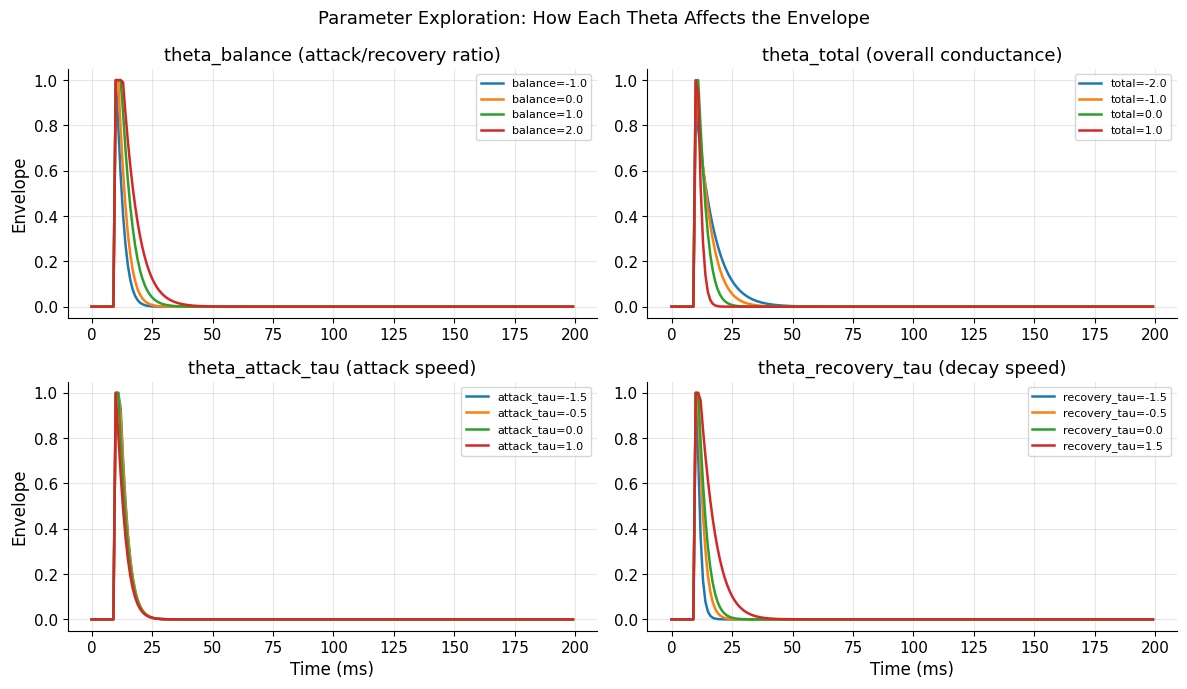

In [7]:
# Explore parameter effects
duration_ms = 200
input_signal = np.zeros(duration_ms)
input_signal[10] = 1.5

# Vary theta_balance: attack-biased vs recovery-biased
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# Top left: vary theta_balance
for balance in [-1.0, 0.0, 1.0, 2.0]:
    unit = HHEnvelopeUnit()
    unit.set_theta(theta_balance=balance)
    env, _ = run_heu_simulation(unit, input_signal)
    axes[0, 0].plot(env, label=f"balance={balance:.1f}")
axes[0, 0].set_title("theta_balance (attack/recovery ratio)")
axes[0, 0].legend(fontsize=8)
axes[0, 0].set_ylabel("Envelope")

# Top right: vary theta_total
for total in [-2.0, -1.0, 0.0, 1.0]:
    unit = HHEnvelopeUnit()
    unit.set_theta(theta_total=total)
    env, _ = run_heu_simulation(unit, input_signal)
    axes[0, 1].plot(env, label=f"total={total:.1f}")
axes[0, 1].set_title("theta_total (overall conductance)")
axes[0, 1].legend(fontsize=8)

# Bottom left: vary theta_attack_tau
for attack_tau in [-1.5, -0.5, 0.0, 1.0]:
    unit = HHEnvelopeUnit()
    unit.set_theta(theta_attack_tau=attack_tau)
    env, _ = run_heu_simulation(unit, input_signal)
    axes[1, 0].plot(env, label=f"attack_tau={attack_tau:.1f}")
axes[1, 0].set_title("theta_attack_tau (attack speed)")
axes[1, 0].legend(fontsize=8)
axes[1, 0].set_xlabel("Time (ms)")
axes[1, 0].set_ylabel("Envelope")

# Bottom right: vary theta_recovery_tau
for recovery_tau in [-1.5, -0.5, 0.0, 1.5]:
    unit = HHEnvelopeUnit()
    unit.set_theta(theta_recovery_tau=recovery_tau)
    env, _ = run_heu_simulation(unit, input_signal)
    axes[1, 1].plot(env, label=f"recovery_tau={recovery_tau:.1f}")
axes[1, 1].set_title("theta_recovery_tau (decay speed)")
axes[1, 1].legend(fontsize=8)
axes[1, 1].set_xlabel("Time (ms)")

fig.suptitle("Parameter Exploration: How Each Theta Affects the Envelope", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Audio Demonstration

Let's hear the difference between ADSR and HEU envelopes as amplitude modulation on a carrier tone.

In [9]:
# Create staccato and legato HEU envelopes for audio
duration_ms = 300

# Staccato: single pulse
unit = HHEnvelopeUnit()
sig = np.zeros(duration_ms)
sig[5] = 1.5
staccato_env, _ = run_heu_simulation(unit, sig)

# Legato: pulse + tonic
unit = HHEnvelopeUnit()
sig = np.zeros(duration_ms)
sig[5] = 1.5
sig[25:250] = 0.3  # tonic drive
legato_env, _ = run_heu_simulation(unit, sig)

# Convert to audio
staccato_audio, sr = envelope_to_audio(staccato_env, carrier_freq=440.0)
legato_audio, sr = envelope_to_audio(legato_env, carrier_freq=440.0)

print("Staccato (single pulse, no tonic):")
display_audio(staccato_audio, sr)

print("\nLegato (pulse + tonic drive):")
display_audio(legato_audio, sr)

Staccato (single pulse, no tonic):



Legato (pulse + tonic drive):


## 8. Summary: The HEU as a Musical Primitive

The HEU is not a "better ADSR". It's a fundamentally different approach:

| Property | ADSR | HEU |
|---|---|---|
| Shape source | Pre-programmed | Emergent from dynamics |
| Context sensitivity | None | Refractory, tonic, coupling |
| Accent response | Manual gain scaling | Natural compression (1.5x in → 1.19x out) |
| Sustain mechanism | Hold at level | Tonic-driven positive feedback |
| Parameters | Direct (ms, level) | Indirect (theta → dynamics → envelope) |
| Learnability | Fixed per patch | Optimizable via CMA-ES |

### What's Next

- **Notebook 01**: Tempo locking - the HEU phase-locks to rhythmic input
- **Notebook 02**: Two-voice coupling - consonance-weighted interaction
- **Notebook 03**: Envelope fitting - learn parameters to match target articulations
- **Notebook 04**: Impossibility proof - what single-voice can't do
- **Notebook 05**: Advanced topics - interpolation, phrase-level modulation

---

## Exercises

### Exercise 1: Refractory Exploration

Modify the refractory period and observe how it affects double-pulse response.
Try `refractory_ref_ms` values of 5, 10, 20, 50.

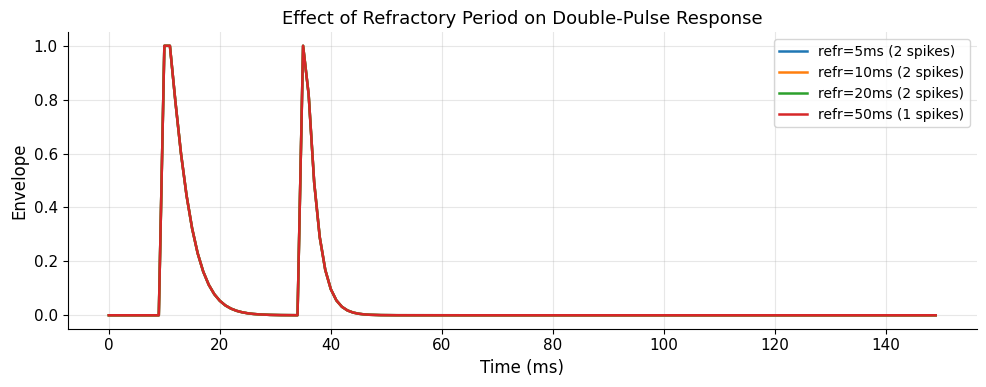

In [9]:
# Exercise 1: Try different refractory periods
# Hint: Use HEUConfig(refractory_ref_ms=...) to change the period


duration_ms = 150
input_signal = np.zeros(duration_ms)
input_signal[10] = 1.5
input_signal[35] = 1.5  # 25ms gap

fig, ax = plt.subplots(figsize=(10, 4))

for refractory in [5, 10, 20, 50]:
    config = HEUConfig(refractory_ref_ms=refractory)
    unit = HHEnvelopeUnit(config=config)
    env, spikes = run_heu_simulation(unit, input_signal)
    ax.plot(env, label=f"refr={refractory}ms ({len(spikes)} spikes)")

ax.set_title("Effect of Refractory Period on Double-Pulse Response")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.legend()
plt.tight_layout()
plt.show()

### Exercise 2: Tonic Level Sweep

How much tonic drive is needed to sustain the envelope above 0.5? Try values from 0.05 to 0.5.

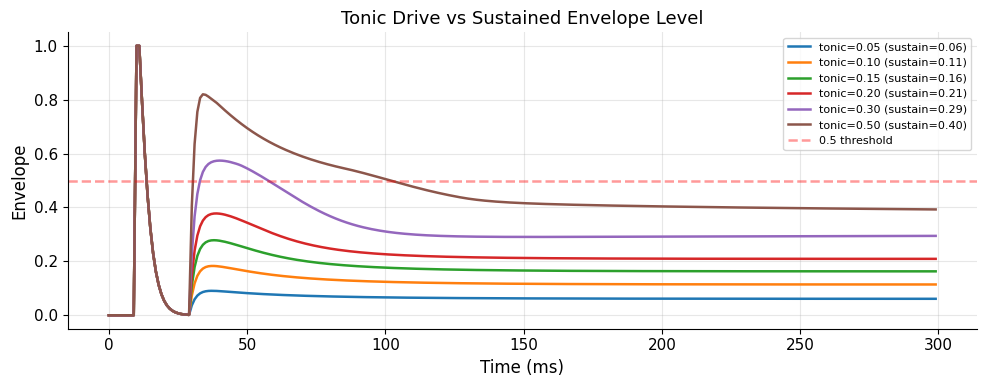

In [10]:
# Exercise 2: Find the minimum tonic for sustained output

duration_ms = 300
fig, ax = plt.subplots(figsize=(10, 4))

for tonic_level in [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]:
    unit = HHEnvelopeUnit()
    sig = np.zeros(duration_ms)
    sig[10] = 1.5  # Initial pulse
    sig[30:] = tonic_level  # Tonic from 30ms onward
    env, _ = run_heu_simulation(unit, sig)
    sustain_level = env[200]  # Check at 200ms
    ax.plot(env, label=f"tonic={tonic_level:.2f} (sustain={sustain_level:.2f})")

ax.axhline(0.5, color="red", linestyle="--", alpha=0.4, label="0.5 threshold")
ax.set_title("Tonic Drive vs Sustained Envelope Level")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Envelope")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()